# Phase 4 — Momentum scanner and themes

**Purpose.** Phases 1 to 3 asked "how much to risk". This phase asks
"on what". It scans a universe of US stocks, keeps the leaders that fit
your rules, scores each setup, and groups the survivors into **themes** so
that two slots are never one bet.

**Mission.**

1. Is the market regime gate open?
2. Which stocks lead, move enough (ADR) and trade enough (liquidity)?
3. Which of them sit in a tight consolidation, not extended?
4. Which candidates move together, and are therefore one theme?

**The linear algebra.** The returns matrix `R` has one row per day and one
column per stock. The covariance matrix is `Σ = RᵀR / (T − 1)` on centred
returns. Its eigenvectors (PCA) are the hidden drivers. A correlation
matrix is also the adjacency matrix of a graph: stocks are nodes,
strong correlations are edges, tightly linked groups are themes.

**Read this first.** The universe is 180 hand-picked liquid names, not the
whole market. The thresholds and the score weights are starting values and
have **not** been tested against forward returns. The scan is a list of
charts to look at, not a list of trades to take. Study tool, not advice.

**Update from Phase 7.** The setup score has now been backtested (`07_score_backtest.ipynb`). Over five years it did not rank candidates: high-score trades did no better than low-score trades. Treat the candidate list as unordered until a score passes that test.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

import lab_style as ls
import scanner as sc

ls.use_lab_style()
pd.set_option("display.width", 200)

In [2]:
# ============================================================
# KEY IN HERE
# ============================================================
REFRESH = False          # True = download fresh prices (needs internet)
                         # False = use the snapshot saved in the data folder

MIN_PRICE        = 5.0   # $ per share
MIN_DOLLAR_VOL_M = 20.0  # average daily dollar volume, $ million
MIN_ADR          = 4.0   # average daily range, %
MIN_MOM_RANK     = 90.0  # momentum percentile (90 = top 10% of the universe)
THEME_CORR       = 0.60  # correlation at or above this links two stocks
CORR_LOOKBACK    = 120   # trading days of returns used for correlation

## Step 1 — Load prices

Four tables (Close, High, Low, Volume). Each is a matrix: rows are trading
days, columns are tickers.

In [3]:
prices = sc.load_prices(refresh=REFRESH)
close = prices["Close"]

print(f"Price matrix shape: {close.shape}  (days, tickers incl. SPY and QQQ)")
print(f"From {close.index[0].date()} to {close.index[-1].date()}")
close.iloc[-3:, :6].round(2)

Price matrix shape: (251, 182)  (days, tickers incl. SPY and QQQ)
From 2025-11-14 to 2026-11-13


,AA,AAPL,ABBV,ABNB,ADBE,AFRM
Date,,,,,,
2026-11-11,41.04,355.36,294.98,181.13,237.60,67.84
2026-11-12,40.45,354.88,294.45,181.13,238.54,65.84
2026-11-13,39.74,356.27,295.03,186.78,243.08,65.11


## Step 2 — The market regime gate

Your rule: take breakouts only when the 10-day MA is above the 20-day MA
and both are rising. The gate is checked on QQQ.

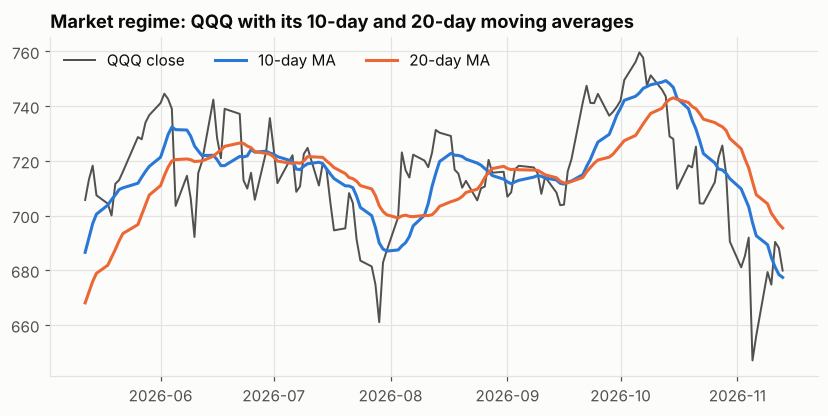

QQQ close 679.89 | 10-day MA 677.40 | 20-day MA 695.45
REGIME GATE: CLOSED
Your rule says no new breakout entries while the gate is closed.
The scan below is then a watch list, not a buy list.


In [4]:
regime = sc.market_regime(close, "QQQ")
px = close["QQQ"].iloc[-130:]
ma10 = close["QQQ"].rolling(10).mean().iloc[-130:]
ma20 = close["QQQ"].rolling(20).mean().iloc[-130:]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(px.index, px, color=ls.TEXT_SOFT, lw=1.3, label="QQQ close")
ax.plot(ma10.index, ma10, color=ls.BLUE, label="10-day MA")
ax.plot(ma20.index, ma20, color=ls.ORANGE, label="20-day MA")
ax.set_title("Market regime: QQQ with its 10-day and 20-day moving averages")
ax.legend(loc="upper left", ncol=3)
plt.show()

state = "OPEN" if regime["gate_open"] else "CLOSED"
print(f"QQQ close {regime['close']:.2f} | 10-day MA {regime['ma10']:.2f} | "
      f"20-day MA {regime['ma20']:.2f}")
print(f"REGIME GATE: {state}")
if not regime["gate_open"]:
    print("Your rule says no new breakout entries while the gate is closed.")
    print("The scan below is then a watch list, not a buy list.")

## Step 3 — Metrics for every stock

| Column | Meaning |
|---|---|
| `ret_1m`, `ret_3m`, `ret_6m` | price change over 21, 63 and 126 trading days |
| `mom_rank` | best percentile rank of the three returns (100 = strongest) |
| `adr_pct` | average daily range: mean of (high ÷ low − 1) over 20 days, % |
| `dollar_vol_m` | average of (close × volume) over 20 days, $ million |
| `trend_ok` | the stock's own 10-day MA above its 20-day MA, both rising |
| `ext_adr` | distance of price above the 10-day MA, in ADR units |
| `tightness` | 5-day average range ÷ 20-day average range (below 1 = contracting) |
| `vol_dryup` | 5-day average volume ÷ 50-day average volume (below 1 = fading) |

In [5]:
metrics = sc.compute_metrics(prices)
print(f"Stocks with full data: {len(metrics)}")
metrics.sort_values("mom_rank", ascending=False).head(8).round(2)

Stocks with full data: 180


,price,ret_1m,ret_3m,ret_6m,adr_pct,dollar_vol_m,trend_ok,above_ma50,ext_adr,tightness,vol_dryup,mom_rank
APP,409.10,0.46,0.31,-0.18,5.42,1846.85,True,True,3.08,1.04,0.91,100.00
MRNA,223.37,-0.06,2.47,3.55,10.20,3356.18,True,True,-0.78,0.70,0.59,100.00
REGN,955.47,0.20,0.19,0.37,3.62,910.68,True,True,0.53,1.01,1.19,99.44
RBLX,49.91,-0.02,0.32,0.16,5.81,489.52,False,True,0.27,0.77,0.75,99.44
OKTA,182.87,-0.12,0.28,1.21,7.00,940.96,False,False,0.16,0.92,0.58,99.44
TTD,15.68,0.19,0.17,-0.26,5.04,300.41,True,True,2.09,1.52,2.04,98.89
ELF,117.98,0.02,0.26,1.09,4.63,174.74,True,True,0.57,0.87,1.20,98.89
SNOW,291.00,-0.13,-0.12,0.85,4.66,1300.26,False,False,0.08,1.04,0.81,98.33


## Step 4 — The filter funnel

Filters are applied in order. Each bar is the number of stocks still alive.

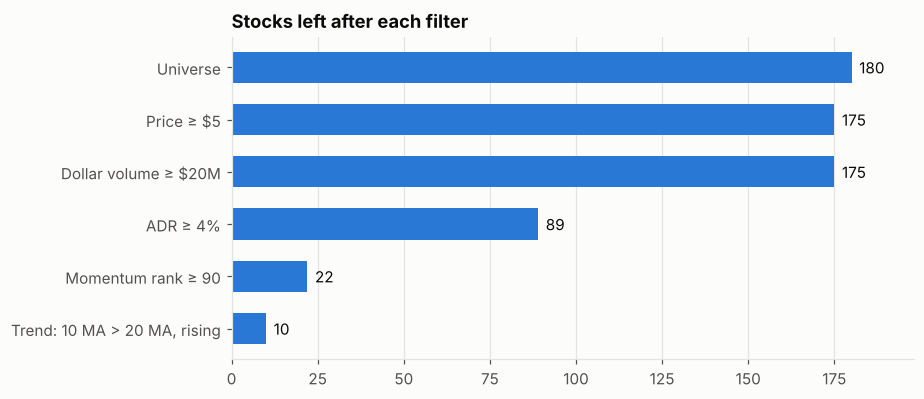

In [6]:
flt = sc.apply_filters(metrics, MIN_PRICE, MIN_DOLLAR_VOL_M, MIN_ADR, MIN_MOM_RANK)
steps = [("Universe", None), (f"Price ≥ ${MIN_PRICE:.0f}", "f_price"),
         (f"Dollar volume ≥ ${MIN_DOLLAR_VOL_M:.0f}M", "f_liquid"),
         (f"ADR ≥ {MIN_ADR:.0f}%", "f_adr"),
         (f"Momentum rank ≥ {MIN_MOM_RANK:.0f}", "f_leader"),
         ("Trend: 10 MA > 20 MA, rising", "f_trend")]
alive = pd.Series(True, index=flt.index)
counts = []
for label, column in steps:
    if column:
        alive &= flt[column]
    counts.append(int(alive.sum()))

fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [s[0] for s in steps][::-1]
ax.barh(labels, counts[::-1], color=ls.BLUE, height=0.6)
for y, v in enumerate(counts[::-1]):
    ax.annotate(str(v), (v, y), textcoords="offset points", xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, max(counts) * 1.1); ax.grid(axis="y", visible=False)
ax.set_title("Stocks left after each filter")
plt.show()

## Chart — The momentum map

Every stock: how much it moves in a day (ADR) against its 3-month return.
The candidates that passed every filter are highlighted and named.

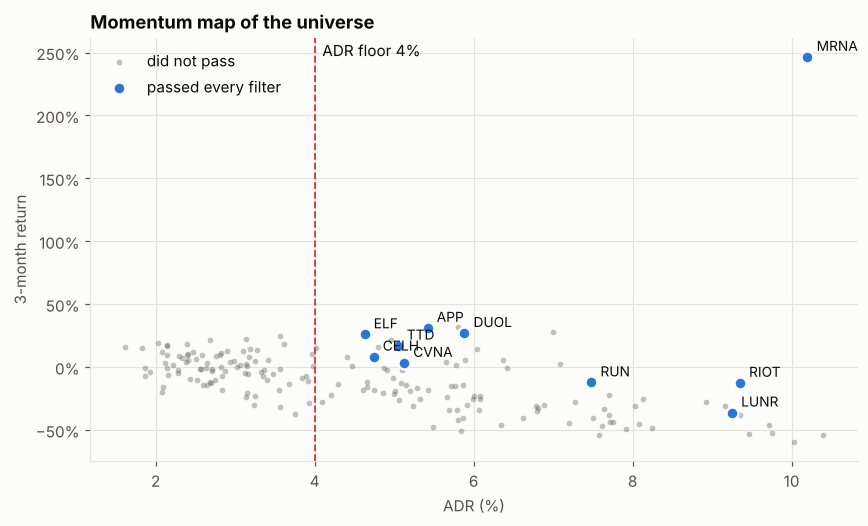

In [7]:
passed = flt[flt["passed"]].copy()
passed["score"] = sc.setup_score(passed)
passed = passed.sort_values("score", ascending=False)
others = flt[~flt["passed"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(others["adr_pct"], 100 * others["ret_3m"], s=14, color=ls.TEXT_SOFT,
           alpha=0.35, linewidths=0, label="did not pass")
ax.scatter(passed["adr_pct"], 100 * passed["ret_3m"], s=60, color=ls.BLUE,
           edgecolor=ls.SURFACE, linewidth=1.5, zorder=3, label="passed every filter")
for ticker, row_ in passed.iterrows():
    ax.annotate(ticker, (row_["adr_pct"], 100 * row_["ret_3m"]),
                textcoords="offset points", xytext=(6, 4), color=ls.TEXT, fontsize=9)
ax.axvline(MIN_ADR, color=ls.CRITICAL, lw=1.2, ls="--")
ax.annotate(f"ADR floor {MIN_ADR:.0f}%", (MIN_ADR, ax.get_ylim()[1]),
            textcoords="offset points", xytext=(5, -12), color=ls.TEXT)
ax.set_ylim(top=min(ax.get_ylim()[1], 300))
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_xlabel("ADR (%)"); ax.set_ylabel("3-month return")
ax.set_title("Momentum map of the universe")
ax.legend(loc="upper left")
plt.show()

## Step 5 — Score each candidate

| Points | Part | Full marks when |
|---|---|---|
| 40 | momentum rank | rank is 100 |
| 25 | tightness | recent ranges are half of the month's ranges |
| 15 | volume dry-up | recent volume is half of the 50-day volume |
| 20 | not extended | price sits on the 10-day MA |

The weights are a starting guess. They rank the list; they do not predict.

       price  ret_1m  ret_3m  ret_6m  adr_pct  dollar_vol_m  ext_adr  tightness  vol_dryup  mom_rank  score
MRNA  223.37    -6.0   247.0   355.0    10.20       3356.18    -0.78       0.70       0.59    100.00   84.2
CELH   32.42    15.0     8.0     7.0     4.74        175.24     0.53       0.80       0.75     95.56   77.0
CVNA   72.37    19.0     3.0     8.0     5.12        738.65    -0.24       0.94       0.82     98.33   76.7
ELF   117.98     2.0    26.0   109.0     4.63        174.74     0.57       0.87       1.20     98.89   68.8
RUN     8.63    13.0   -12.0   -38.0     7.48        107.57    -0.58       0.92       1.10     92.22   63.6
RIOT   17.52    13.0   -13.0   -25.0     9.35        420.83     0.87       0.82       1.26     92.78   61.4
DUOL  165.31    11.0    27.0    48.0     5.88        238.52     1.25       1.07       1.05     97.78   57.5
APP   409.10    46.0    31.0   -18.0     5.42       1846.85     3.08       1.04       0.91    100.00   55.5
LUNR   13.00    12.0   -36.0

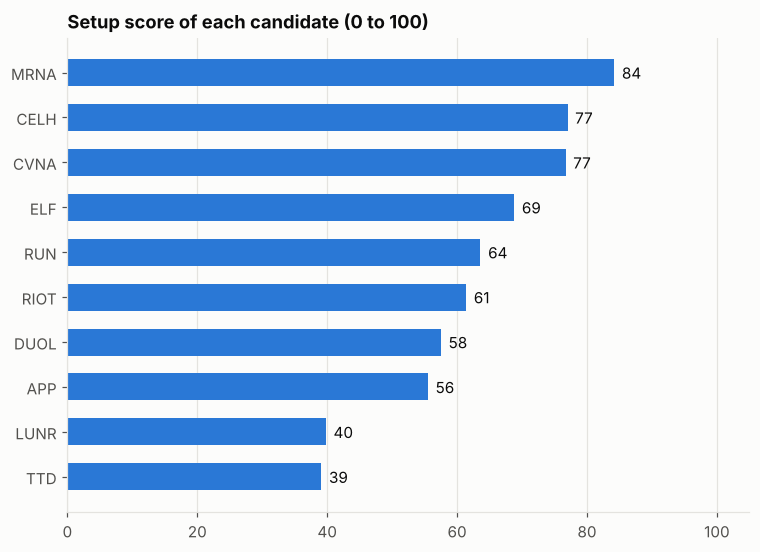

In [8]:
show = passed[["price", "ret_1m", "ret_3m", "ret_6m", "adr_pct", "dollar_vol_m",
               "ext_adr", "tightness", "vol_dryup", "mom_rank", "score"]].copy()
for column in ["ret_1m", "ret_3m", "ret_6m"]:
    show[column] = (100 * show[column]).round(0)
print(show.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 0.42 * len(passed) + 1.4))
order = passed.index[::-1]
ax.barh(order, passed.loc[order, "score"], color=ls.BLUE, height=0.6)
for y, t in enumerate(order):
    ax.annotate(f"{passed.loc[t, 'score']:.0f}", (passed.loc[t, "score"], y),
                textcoords="offset points", xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, 105); ax.grid(axis="y", visible=False)
ax.set_title("Setup score of each candidate (0 to 100)")
plt.show()

## Step 6 — The returns matrix and the covariance matrix

Themes need a wider group than the final candidates, so that links between
sectors are visible. The group used here is every stock that passes the
price, liquidity and ADR filters.

The covariance matrix is built by hand, `Σ = RᵀR / (T − 1)` on centred
returns, and checked against NumPy.

In [9]:
group = flt[flt["f_price"] & flt["f_liquid"] & flt["f_adr"]].index
returns = sc.returns_matrix(close, group, CORR_LOOKBACK)
R = returns.to_numpy()
T, N = R.shape

centred = R - R.mean(axis=0)                 # subtract each column's mean
Sigma = centred.T @ centred / (T - 1)        # (N, T) @ (T, N) -> (N, N)
vol = np.sqrt(np.diag(Sigma))                # daily volatility of each stock
corr = pd.DataFrame(Sigma / np.outer(vol, vol), index=group, columns=group)

print(f"Returns matrix R: {R.shape}  (days, stocks)")
print(f"Covariance Σ    : {Sigma.shape}")
print(f"Matches np.cov  : {np.allclose(Sigma, np.cov(R, rowvar=False))}")
upper = corr.to_numpy()[np.triu_indices(N, k=1)]
print(f"Pairs: {len(upper):,}   median correlation: {np.median(upper):.2f}   "
      f"pairs at or above {THEME_CORR}: {np.mean(upper >= THEME_CORR):.1%}")

Returns matrix R: (120, 89)  (days, stocks)
Covariance Σ    : (89, 89)
Matches np.cov  : True
Pairs: 3,916   median correlation: 0.27   pairs at or above 0.6: 7.8%


## Step 7 — PCA: how many hidden drivers?

Each eigenvector of the correlation matrix is one driver. Its eigenvalue,
as a share of the total, is how much of all the movement it explains.

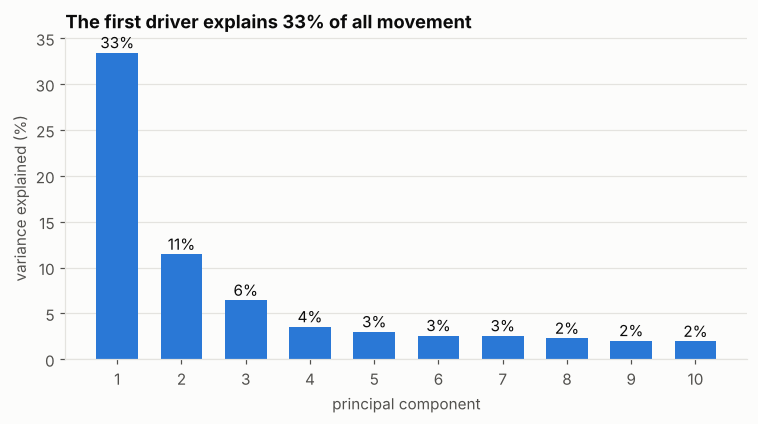

Stocks with a positive loading on driver 1: 98%
Drivers needed to explain half of the movement: 3 of 89


In [10]:
values, vectors, share = sc.pca(returns)
pc1 = pd.Series(vectors[:, 0], index=group)
if pc1.sum() < 0:                     # the sign of an eigenvector is arbitrary
    pc1 = -pc1

fig, ax = plt.subplots(figsize=(8, 3.8))
k = 10
ax.bar(np.arange(1, k + 1), 100 * share[:k], color=ls.BLUE, width=0.65)
for i in range(k):
    ax.annotate(f"{100 * share[i]:.0f}%", (i + 1, 100 * share[i]), ha="center",
                textcoords="offset points", xytext=(0, 3), color=ls.TEXT)
ax.set_xticks(np.arange(1, k + 1)); ax.grid(axis="x", visible=False)
ax.set_xlabel("principal component"); ax.set_ylabel("variance explained (%)")
ax.set_title(f"The first driver explains {100 * share[0]:.0f}% of all movement")
plt.show()

print(f"Stocks with a positive loading on driver 1: {np.mean(pc1 > 0):.0%}")
print(f"Drivers needed to explain half of the movement: "
      f"{int(np.searchsorted(np.cumsum(share), 0.5) + 1)} of {N}")

When almost every stock loads the same way on driver 1, that driver is
**the market**. High-ADR momentum stocks share it. This is why two "different"
momentum names often fall on the same day.

## Step 8 — Themes: the correlation matrix as a graph

Link two stocks when their correlation is at or above the threshold. The
links form a graph. A theme is a **community** of that graph: a set of
stocks with many links inside and few links to the outside. A stock with
no link is `solo`.

In [11]:
themes, graph = sc.find_themes(corr, THEME_CORR)
sizes = themes[themes != "solo"].value_counts()
print(f"Stocks: {N}   links: {graph.number_of_edges()}   "
      f"themes: {len(sizes)}   solo stocks: {int((themes == 'solo').sum())}\n")
for name, size in sizes.items():
    members = sorted(themes[themes == name].index)
    print(f"{name} ({size}): {' '.join(members)}")

Stocks: 89   links: 307   themes: 8   solo stocks: 23

T1 (25): ALAB AMAT AMD ANET ARM CEG COHR CRDO ETN GEV INTC KLAC LRCX MCHP MRVL MU NRG ON PWR QCOM STX TXN VRT VST WDC
T2 (13): ASTS AVAV IONQ KTOS LEU LUNR MP NNE OKLO QBTS RGTI RKLB UEC
T3 (12): AI CRWD DDOG FTNT MDB NET NOW OKTA PANW S SNOW ZS
T4 (6): AFRM COIN HOOD MSTR SOFI UPST
T5 (4): CLSK IREN MARA RIOT
T6 (2): ENPH SEDG
T7 (2): MPC VLO
T8 (2): RBLX RDDT


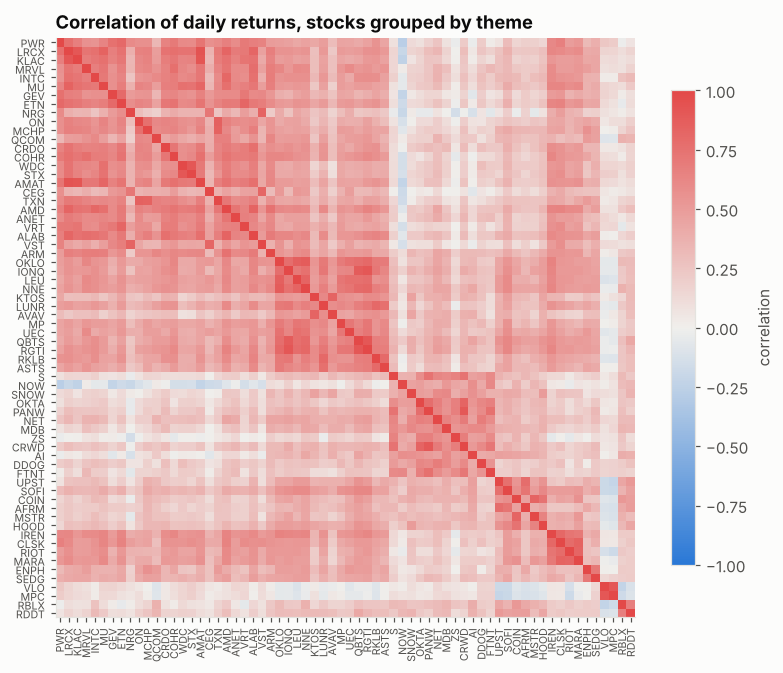

In [12]:
# Heatmap, with stocks ordered so that each theme forms a block.
ordered = themes.map(lambda t: (1, "") if t == "solo" else (0, t)).sort_values().index
in_theme = [t for t in ordered if themes[t] != "solo"]
blue_red = LinearSegmentedColormap.from_list("blue_red", [ls.BLUE, "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.loc[in_theme, in_theme], cmap=blue_red, vmin=-1, vmax=1)
ax.set_xticks(range(len(in_theme))); ax.set_xticklabels(in_theme, rotation=90, fontsize=7)
ax.set_yticks(range(len(in_theme))); ax.set_yticklabels(in_theme, fontsize=7)
ax.grid(False)
ax.set_title("Correlation of daily returns, stocks grouped by theme")
fig.colorbar(im, ax=ax, label="correlation", shrink=0.8)
plt.show()

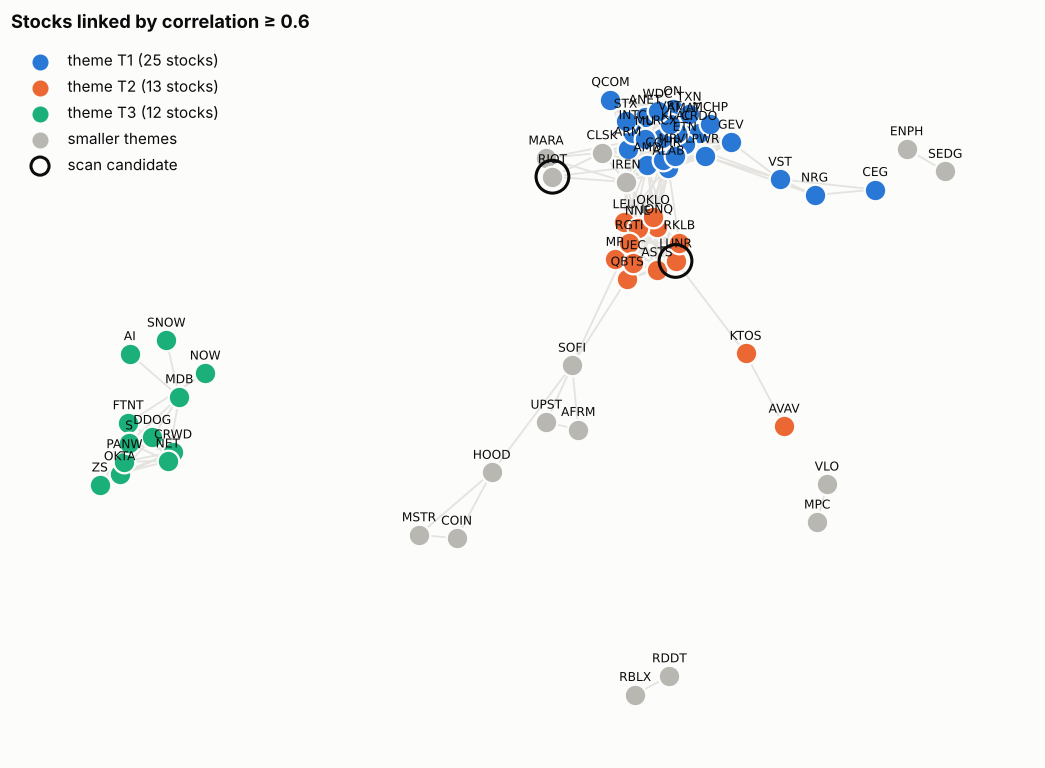

In [13]:
# Network graph. The three largest themes get a colour; the rest are grey.
top3 = list(sizes.index[:3])
palette = dict(zip(top3, [ls.BLUE, ls.ORANGE, ls.AQUA]))
linked = [n for n in graph.nodes if themes[n] != "solo"]
sub = graph.subgraph(linked)
pos = nx.spring_layout(sub, seed=5, k=1.7, iterations=400, weight=None)

fig, ax = plt.subplots(figsize=(12, 8.5))
nx.draw_networkx_edges(sub, pos, ax=ax, edge_color=ls.GRID, width=1.2)
for theme in list(sizes.index):
    nodes = [n for n in sub.nodes if themes[n] == theme]
    nx.draw_networkx_nodes(sub, pos, nodelist=nodes, ax=ax, node_size=200,
                           node_color=palette.get(theme, "#b8b7b2"),
                           edgecolors=ls.SURFACE, linewidths=1.5)
candidates_here = [n for n in sub.nodes if n in passed.index]
nx.draw_networkx_nodes(sub, pos, nodelist=candidates_here, ax=ax, node_size=460,
                       node_color="none", edgecolors=ls.TEXT, linewidths=2)
nx.draw_networkx_labels(sub, {n: (x, y + 0.04) for n, (x, y) in pos.items()},
                        ax=ax, font_size=8, font_color=ls.TEXT)
for theme, color in palette.items():
    ax.scatter([], [], s=90, color=color, label=f"theme {theme} ({sizes[theme]} stocks)")
ax.scatter([], [], s=90, color="#b8b7b2", label="smaller themes")
ax.scatter([], [], s=140, facecolor="none", edgecolor=ls.TEXT, linewidth=2,
           label="scan candidate")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.0))
ax.set_title(f"Stocks linked by correlation ≥ {THEME_CORR}")
ax.axis("off")
plt.show()

## Step 9 — The candidate list, with themes

Rule B1: one theme is one bet. From each theme keep only the best-scored
candidate. `solo` candidates each count as their own theme.

In [14]:
final = passed.copy()
final["theme"] = themes.reindex(final.index).fillna("solo")
key = np.where(final["theme"] == "solo", final.index, final["theme"])
final["best_in_theme"] = ~pd.Series(key, index=final.index).duplicated()

out = final[["price", "adr_pct", "mom_rank", "ext_adr", "tightness", "score",
             "theme", "best_in_theme"]].round(2)
print(out.to_string())

out.to_csv("candidates.csv")
print(f"\nSaved {len(out)} candidates to candidates.csv (input for Phase 5).")
print(f"Regime gate: {state}")

       price  adr_pct  mom_rank  ext_adr  tightness  score theme  best_in_theme
MRNA  223.37    10.20    100.00    -0.78       0.70   84.2  solo           True
CELH   32.42     4.74     95.56     0.53       0.80   77.0  solo           True
CVNA   72.37     5.12     98.33    -0.24       0.94   76.7  solo           True
ELF   117.98     4.63     98.89     0.57       0.87   68.8  solo           True
RUN     8.63     7.48     92.22    -0.58       0.92   63.6  solo           True
RIOT   17.52     9.35     92.78     0.87       0.82   61.4    T5           True
DUOL  165.31     5.88     97.78     1.25       1.07   57.5  solo           True
APP   409.10     5.42    100.00     3.08       1.04   55.5  solo           True
LUNR   13.00     9.25     91.11     1.80       1.14   39.8    T2           True
TTD    15.68     5.04     98.89     2.09       1.52   39.1  solo           True

Saved 10 candidates to candidates.csv (input for Phase 5).
Regime gate: CLOSED


## What this notebook shows

The figures below are for the saved snapshot (prices to 13 Nov 2026).
A refresh will change them.

1. **The regime gate is closed.** QQQ's 10-day MA is below its 20-day MA.
   By your rule the output is a watch list, not a buy list.
2. **The funnel is steep.** 180 stocks, 89 with ADR of 4% or more, 22
   leaders, 10 with their own trend intact.
3. **Leading on any one horizon lets weak names in.** RUN, RIOT and LUNR
   pass on a strong month while down 25% to 62% over six months. Look at
   the chart before trusting the rank.
4. **One driver dominates.** The first principal component explains 33% of
   all movement among the 89 high-ADR stocks, and 98% of them load on it
   the same way. Three drivers explain half of the movement.
5. **Themes are real.** Eight themes appear, for example chips and AI
   power (25 stocks), space, nuclear and quantum (13), software and
   security (12), fintech and crypto (6), bitcoin miners (4).
6. **Most candidates are solo.** Eight of the ten candidates have no
   strong link to another stock; RIOT and LUNR sit in themes T5 and T2.

## What the scanner does not do

- **No forward test.** Nobody has checked that a high score leads to a
  better trade. That needs a backtest.
- **Small, hand-picked universe.** 180 names. "Top 10% of 180" is a far
  weaker claim than "top 1 to 2% of the whole market".
- **Daily data only.** Your entry rules (low of day, first 30 minutes,
  5-minute break) need intraday data and cannot be checked here.
- **No fundamentals or news.** Earnings dates, episodic pivots and
  catalysts are not read. A candidate may report earnings tomorrow.
- **Correlation is one window.** 120 days of Pearson correlation
  understates how stocks fall together in a selloff.
- **A snapshot.** The saved prices are from one day. Set `REFRESH = True`.

## Exercises

1. Set `MIN_MOM_RANK = 80`. How many candidates pass? Does quality fall?
2. Set `THEME_CORR = 0.50`, then `0.70`. How do the themes merge and split?
3. In Step 6, print `Sigma.shape`, `centred.T.shape` and `centred.shape`.
   Explain why the product is (N, N).
4. In Step 7, list the ten stocks with the largest loading on driver 1
   (`pc1.sort_values().tail(10)`). What do they have in common?
5. In `scanner.py`, change the score weights in `setup_score`. Does the
   top candidate change?

Next: Phase 5 takes `candidates.csv` and picks the best two with a linear
program, under cash, theme and gap-risk limits.